# Week 1 — Task 1: Python for Data Science
**Dataset:** Titanic passenger data (source: seaborn-data, https://github.com/mwaskom/seaborn-data)

This notebook covers Python fundamentals (variables, conditionals, loops, functions, collections, exception handling), NumPy, Pandas and Matplotlib, then performs the 8-step data analysis assignment.

## Part A — Python Fundamentals

In [1]:
# Variables & data types
name, age, height, is_student = "Asha", 21, 1.65, True
print(type(name), type(age), type(height), type(is_student))

# Conditional statements
score = 72
if score >= 75:
    grade = "A"
elif score >= 60:
    grade = "B"
else:
    grade = "C"
print("Grade:", grade)

# Loops
for i in range(1, 4):
    print("for loop:", i)
n = 3
while n > 0:
    print("while loop:", n)
    n -= 1

# Functions
def mean(values):
    """Return the average of a list of numbers."""
    return sum(values) / len(values)
print("Mean:", mean([4, 8, 15, 16, 23, 42]))

# Lists, tuples, dictionaries
fruits = ["apple", "banana", "cherry"]; fruits.append("mango")
point = (3, 4)                      # immutable
student = {"name": "Asha", "marks": [80, 90]}
student["city"] = "Pune"
print(fruits, point, student)

# Exception handling
def safe_divide(a, b):
    try:
        return a / b
    except ZeroDivisionError:
        return "Cannot divide by zero"
    finally:
        pass
print(safe_divide(10, 2), "|", safe_divide(5, 0))

<class 'str'> <class 'int'> <class 'float'> <class 'bool'>
Grade: B
for loop: 1
for loop: 2
for loop: 3
while loop: 3
while loop: 2
while loop: 1
Mean: 18.0
['apple', 'banana', 'cherry', 'mango'] (3, 4) {'name': 'Asha', 'marks': [80, 90], 'city': 'Pune'}
5.0 | Cannot divide by zero


## Part B — NumPy Basics

In [2]:
import numpy as np
arr = np.array([10, 20, 30, 40, 50])
print("Mean:", arr.mean(), "| Std:", arr.std().round(2), "| Sum:", arr.sum())
m = np.arange(1, 7).reshape(2, 3)
print(m, "\nTranspose:\n", m.T, "\nDouble:\n", m * 2)

Mean: 30.0 | Std: 14.14 | Sum: 150
[[1 2 3]
 [4 5 6]] 
Transpose:
 [[1 4]
 [2 5]
 [3 6]] 
Double:
 [[ 2  4  6]
 [ 8 10 12]]


## Part C — Practical Assignment (Titanic dataset)

### 1. Load the dataset with Pandas

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 2. Number of rows and columns

In [4]:
rows, cols = df.shape
print(f"Rows: {rows}, Columns: {cols}")

Rows: 891, Columns: 15


### 3. Dataset structure and data types

In [5]:
df.info()
print()
print(df.dtypes.value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB

str        7
int64      4
float64    2
bool       2
Name: count, dtype: int64


### 4. Missing values

In [6]:
missing = df.isnull().sum()
pd.DataFrame({"missing": missing, "percent": (missing/len(df)*100).round(2)})[missing > 0]

,missing,percent
age,177,19.87
embarked,2,0.22
deck,688,77.22
embark_town,2,0.22


### 5. Duplicate records

In [7]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates after:", df.duplicated().sum(), "| Shape:", df.shape)

Duplicates before: 107
Duplicates after: 0 | Shape: (784, 15)


### 6. Basic data cleaning
- `deck` has ~77% missing values, so the column is dropped.
- `age` is filled with the median.
- `embarked` / `embark_town` are filled with the mode.
- Redundant columns `alive` (same as `survived`) and `class` (same as `pclass`) are dropped.

In [8]:
df = df.drop(columns=["deck", "alive", "class"])
df["age"] = df["age"].fillna(df["age"].median())
for c in ["embarked", "embark_town"]:
    df[c] = df[c].fillna(df[c].mode()[0])
print("Remaining missing values:", df.isnull().sum().sum())
df.to_csv("titanic_cleaned.csv", index=False)
df.shape

Remaining missing values: 0


(784, 12)

### 7. Basic statistical insights

In [9]:
display(df.describe().round(2))
print("Overall survival rate: {:.1%}".format(df["survived"].mean()))
display(df.groupby("sex")["survived"].mean().round(3).rename("survival_rate"))
display(df.groupby("pclass")["survived"].mean().round(3).rename("survival_rate"))
display(df.groupby("pclass")["fare"].mean().round(2).rename("avg_fare"))

,survived,pclass,age,sibsp,parch,fare
count,784.00,784.00,784.00,784.00,784.00,784.00
mean,0.41,2.24,29.65,0.52,0.42,34.71
std,0.49,0.86,13.73,0.99,0.84,52.16
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,1.00,22.00,0.00,0.00,8.05
50%,0.00,3.00,28.25,0.00,0.00,15.90
75%,1.00,3.00,36.00,1.00,1.00,34.11
max,1.00,3.00,80.00,8.00,6.00,512.33


Overall survival rate: 41.2%


sex
female    0.741
male      0.216
Name: survival_rate, dtype: float64

pclass
1    0.631
2    0.509
3    0.257
Name: survival_rate, dtype: float64

pclass
1    84.49
2    21.84
3    13.66
Name: avg_fare, dtype: float64

### 8. Visualizations (Matplotlib)

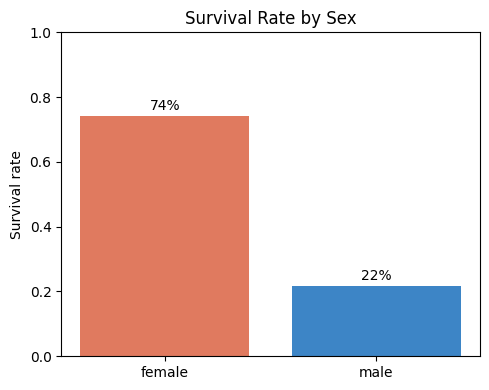

In [10]:
# Chart 1: Survival by sex (bar)
s = df.groupby("sex")["survived"].mean()
plt.figure(figsize=(5,4))
plt.bar(s.index, s.values, color=["#e07a5f", "#3d85c6"])
plt.title("Survival Rate by Sex"); plt.ylabel("Survival rate"); plt.ylim(0,1)
for i, v in enumerate(s.values): plt.text(i, v+0.02, f"{v:.0%}", ha="center")
plt.tight_layout(); plt.savefig("chart1_survival_by_sex.png", dpi=150); plt.show()

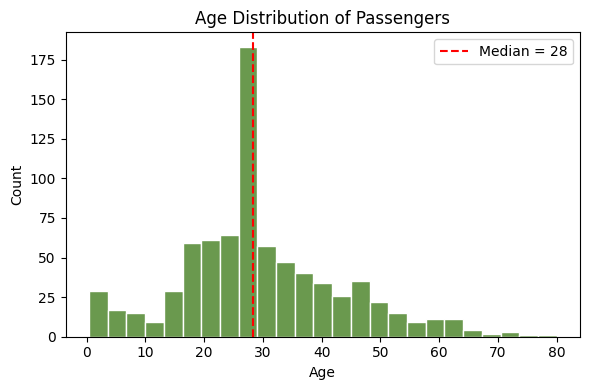

In [11]:
# Chart 2: Age distribution (histogram)
plt.figure(figsize=(6,4))
plt.hist(df["age"], bins=25, color="#6a994e", edgecolor="white")
plt.axvline(df["age"].median(), color="red", linestyle="--", label=f"Median = {df['age'].median():.0f}")
plt.title("Age Distribution of Passengers"); plt.xlabel("Age"); plt.ylabel("Count"); plt.legend()
plt.tight_layout(); plt.savefig("chart2_age_distribution.png", dpi=150); plt.show()

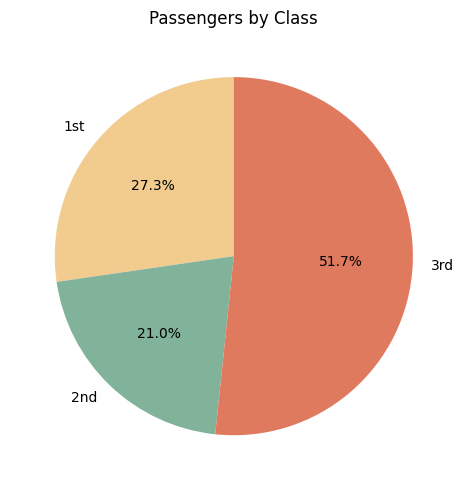

In [12]:
# Chart 3: Passenger class composition (pie)
c = df["pclass"].value_counts().sort_index()
plt.figure(figsize=(5,5))
plt.pie(c.values, labels=["1st", "2nd", "3rd"], autopct="%1.1f%%", startangle=90,
        colors=["#f2cc8f", "#81b29a", "#e07a5f"])
plt.title("Passengers by Class")
plt.tight_layout(); plt.savefig("chart3_class_pie.png", dpi=150); plt.show()

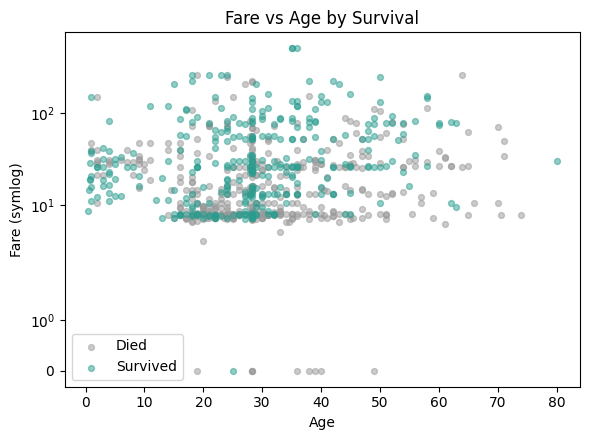

In [13]:
# Chart 4: Fare vs Age scatter, coloured by survival
plt.figure(figsize=(6,4.5))
for val, col, lab in [(0, "#999999", "Died"), (1, "#2a9d8f", "Survived")]:
    sub = df[df["survived"] == val]
    plt.scatter(sub["age"], sub["fare"], c=col, alpha=0.5, s=18, label=lab)
plt.yscale("symlog"); plt.title("Fare vs Age by Survival")
plt.xlabel("Age"); plt.ylabel("Fare (symlog)"); plt.legend()
plt.tight_layout(); plt.savefig("chart4_fare_vs_age.png", dpi=150); plt.show()

## Conclusion
- The dataset has 784 unique passengers after removing 107 duplicate rows (originally 891).
- Women (74.1%) survived far more often than men (21.6%), and survival fell steadily from 1st class (63.1%) to 3rd class (25.7%). Overall survival was 41.2%.
- Most passengers were in 3rd class and aged 20–40; fares are highly right-skewed.